# PTB-XL: Normal vs Abnormal ECG Classification (traditional ML)

An end-to-end, reproducible pipeline built for the **PTB-XL** dataset (`ptbxl_database.csv`).

| Step | What happens |
|---|---|
| 0 | Settings, Drive mount, imports |
| 1 | Load and inspect the CSV |
| 2 | Preprocessing: binary label from `scp_codes`, cleaning, ECG signal processing + feature extraction, train/test split |
| 3 | Exploratory data analysis (training set only) |
| 4 | Train and compare basic models (cross-validation) |
| 5 | Tune the best model and evaluate it |
| 6 | Final test on unseen data |

### Two things you need to know about PTB-XL
**1. The CSV is a metadata table, not the ECG signals.** It holds age, sex, height, weight and the diagnosis codes (`scp_codes`). The actual 12-lead waveforms are stored as separate files in the `records100/` (100 Hz) or `records500/` (500 Hz) folder from [PhysioNet](https://physionet.org/content/ptb-xl/). This notebook therefore has two modes:

| Mode | When | Features |
|---|---|---|
| **Waveform mode** (recommended) | a `records500/` or `records100/` folder is found next to your CSV | ECG-specific preprocessing (filtering, R-peak detection, heart-rate variability, per-lead morphology) + age/sex/height/weight |
| **Metadata mode** | only the CSV is available | age, sex, height, weight, BMI only. This works, but is a much weaker predictor |

**2. Diagnosis-related columns must not be used as features.** `report`, `scp_codes`, `heart_axis`, `infarction_stadium1/2`, `extra_beats`, `pacemaker`, `validated_by*`, `second_opinion` and `initial_autogenerated_report` all come from the diagnosis itself. Using them would be *target leakage*: the model would look brilliant but be useless on a new patient. They are deliberately excluded.

**Honest evaluation rules used here:** by default the official PTB-XL split is used (`strat_fold` 1-9 = training, fold 10 = test; folds never share a patient), cross-validation is grouped by `patient_id`, and imputing/scaling/model fitting happen inside a `Pipeline` so nothing leaks from validation or test data.

## Step 0: Settings, Drive and imports

In [1]:
# ==============  SETTINGS  (the only cell you need to edit)  ==============
DATA_DIR      = "/content/drive/MyDrive/ses 4"   # folder containing ptbxl_database.csv
CSV_NAME      = "ptbxl_database.csv"
WAVEFORM_DIR  = None        # folder that contains "records500/" and/or "records100/". None = same as DATA_DIR
RECORD_TYPE   = "auto"      # "hr" = records500 (500 Hz), "lr" = records100 (100 Hz).
                            # "auto" = use whichever folder exists (if both exist, the faster 100 Hz one)

USE_WAVEFORMS    = "auto"   # "auto" = use ECG waveforms if a records folder is found, otherwise metadata only
                            # True / False = force one mode
USE_DEMOGRAPHICS = True     # waveform mode: also add age, sex, height, weight, BMI as features

NORMAL_MIN_LIKELIHOOD = 50  # a record counts as Normal if NORM has likelihood >= this (and no other diagnosis)

# --- WHICH ECG RECORDS TO LOAD (the full dataset is heavy; every subfolder of records500/ holds ~1000 records) ---
RECORD_DIRS   = None        # subfolders to use, e.g. ["00000"] or ["00000", "01000", "02000"].
                            #   None = ALL folders (heavy)   |   "available" = every folder that exists on your Drive
SPLIT_MODE    = "folds"     # "folds"   = split the loaded records with PTB-XL's official strat_fold:
                            #             folds 1-9 = train, fold 10 = test (patients never shared)
                            # "folders" = train on the folders in TRAIN_DIRS, test on the folders in TEST_DIRS
                            #             (RECORD_DIRS is ignored in this mode)
TRAIN_DIRS    = ["00000", "01000"]
TEST_DIRS     = ["02000"]
TRAIN_STRAT_FOLDS = list(range(1, 10))   # used when SPLIT_MODE = "folds"
TEST_STRAT_FOLD   = 10
N_WORKERS     = 8           # parallel file readers (reading from Drive is the slow part, so more helps)
CACHE_EVERY   = 500         # save the feature cache to Drive after every this many records (survives disconnects)
MAX_RECORDS   = None        # optional extra cap: random subset of the selected records (e.g. 500 for a very quick test)

N_FOLDS          = 5        # cross-validation folds
RANDOM_STATE     = 42
SELECTION_METRIC = "balanced_accuracy"   # metric used to pick the best model: "balanced_accuracy", "roc_auc", "recall", "f1"
                            # (not "f1": ~59% of records are Abnormal, so predicting "Abnormal" for everything already gives F1 of about 0.74)
CV_MAX_SAMPLES   = 20000    # max rows used for model comparison/tuning (final model uses ALL training rows)

In [2]:
# Google Colab only: mount Google Drive (a pop-up will ask for permission)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - skipping Drive mount.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os, ast, time, collections, subprocess, sys, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats

from sklearn.model_selection import (train_test_split, StratifiedGroupKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve)

try:
    from IPython.display import display
except ImportError:
    display = print
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

warnings.filterwarnings("ignore")
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {0: "tab:blue", 1: "tab:red"}
NAMES = {0: "Normal", 1: "Abnormal"}

## Step 1: Data loading and inspection

In [4]:
csv_path = os.path.join(DATA_DIR, CSV_NAME)
raw = pd.read_csv(csv_path, index_col="ecg_id")
print(f"Loaded: {csv_path}")
print(f"Shape: {raw.shape[0]:,} ECG records x {raw.shape[1]} columns   |   unique patients: {raw['patient_id'].nunique():,}")

display(raw[["patient_id", "age", "sex", "height", "weight", "scp_codes", "strat_fold", "filename_hr"]].head())

miss = (raw.isna().mean() * 100).round(1)
print("\nColumns with missing values (% of records):")
print(miss[miss > 0].sort_values(ascending=False).to_string())
print("\nAge describe():")
print(raw["age"].describe().round(1).to_string())
print(f"\nExample of the diagnosis column:  scp_codes = {raw['scp_codes'].iloc[0]}")
print("(dictionary of diagnostic code -> likelihood in %.  NORM = normal ECG, SR = sinus rhythm, ...)")

# Are the ECG waveform files available?  (records500 = 500 Hz "hr" files, records100 = 100 Hz "lr" files)
REC_DIRS = {"lr": "records100", "hr": "records500"}
REC_FS = {"lr": 100, "hr": 500}
wf_root = WAVEFORM_DIR or DATA_DIR
avail = [t for t in ("lr", "hr") if os.path.isdir(os.path.join(wf_root, REC_DIRS[t]))]
rec_type = (avail[0] if avail else "hr") if RECORD_TYPE == "auto" else RECORD_TYPE
wf_found = rec_type in avail
use_wf = wf_found if USE_WAVEFORMS == "auto" else bool(USE_WAVEFORMS)
if use_wf and not wf_found:
    raise FileNotFoundError(f"No '{REC_DIRS[rec_type]}' folder was found in {wf_root}. Check WAVEFORM_DIR / RECORD_TYPE, "
                            "or set USE_WAVEFORMS=False for metadata-only mode.")
FS = REC_FS[rec_type]                                     # sampling rate of the chosen records (Hz)
FILENAME_COL = f"filename_{rec_type}"                     # column of the CSV holding the record paths
print("\n" + "=" * 70)
if use_wf:
    print(f"MODE: WAVEFORM  - ECG signals found in {wf_root}/{REC_DIRS[rec_type]}  ({FS} Hz, column '{FILENAME_COL}')")
else:
    print("MODE: METADATA ONLY - no 'records500' / 'records100' folder found, so no ECG signals are available.")
    print("      The model can only use age, sex, height, weight and BMI, so expect modest performance.")
    print("      For real ECG signal processing, add the PTB-XL records500/ (or records100/) folder and re-run.")
print("=" * 70)

Loaded: /content/drive/MyDrive/ses 4/ptbxl_database.csv
Shape: 21,799 ECG records x 27 columns   |   unique patients: 18,869


,patient_id,age,sex,height,weight,scp_codes,strat_fold,filename_hr
ecg_id,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",3,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,"{'NORM': 80.0, 'SBRAD': 0.0}",2,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,"{'NORM': 100.0, 'SR': 0.0}",5,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,"{'NORM': 100.0, 'SR': 0.0}",3,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,"{'NORM': 100.0, 'SR': 0.0}",4,records500/00000/00005_hr



Columns with missing values (% of records):
electrodes_problems    99.9
infarction_stadium2    99.5
pacemaker              98.7
burst_noise            97.2
baseline_drift         92.7
extra_beats            91.1
static_noise           85.0
infarction_stadium1    74.3
height                 68.0
weight                 56.8
validated_by           43.0
heart_axis             38.8
nurse                   6.8
site                    0.1

Age describe():
count    21799.0
mean        62.8
std         32.3
min          2.0
25%         50.0
50%         62.0
75%         72.0
max        300.0

Example of the diagnosis column:  scp_codes = {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
(dictionary of diagnostic code -> likelihood in %.  NORM = normal ECG, SR = sinus rhythm, ...)

MODE: WAVEFORM  - ECG signals found in /content/drive/MyDrive/ses 4/records100  (100 Hz, column 'filename_lr')


## Step 2: Data preprocessing

### 2.1 Binary target from `scp_codes`: Normal (0) vs Abnormal (1)
`scp_codes` holds the diagnostic statements with a likelihood (0-100). The rule used here:

- **Normal (0):** `NORM` has likelihood >= 50 **and** no other diagnostic statement (other than `SR` = sinus rhythm, a normal rhythm label, and zero-likelihood form/rhythm remarks).
- **Abnormal (1):** any other diagnostic statement is present with likelihood > 0. This includes records that say `NORM` but *also* carry a pathology such as a bundle-branch block.
- **Excluded (uncertain):** records with a weak `NORM` (< 50) and no pathology, or with only `SR`. They are neither clearly normal nor clearly abnormal.

In [5]:
IGNORE_CODES = {"NORM", "SR"}          # not counted as "other diagnoses"

def make_label(codes):
    # returns (label, reason): label 0 = Normal, 1 = Abnormal, NaN = uncertain (excluded)
    norm = codes.get("NORM", 0)
    other = [k for k, v in codes.items() if k not in IGNORE_CODES and v > 0]
    if other:
        return 1, ("Abnormal: NORM + another diagnosis" if norm > 0 else "Abnormal: other diagnosis")
    if norm >= NORMAL_MIN_LIKELIHOOD:
        return 0, "Normal"
    return np.nan, "Excluded: uncertain (weak/no NORM, no diagnosis)"

codes_all = raw["scp_codes"].apply(ast.literal_eval)
lab = codes_all.apply(make_label)
meta = raw.copy()
meta["codes"] = codes_all
meta["label"] = lab.str[0]
meta["label_reason"] = lab.str[1]

print("How every record was labelled:")
display(meta["label_reason"].value_counts().rename("records").to_frame())

meta = meta[meta["label"].notna()].copy()
meta["label"] = meta["label"].astype(int)
meta["rec_folder"] = meta[FILENAME_COL].str.split("/").str[1]           # e.g. 'records500/00000/00001_hr' -> '00000'

if SPLIT_MODE == "folders" and not use_wf:
    print("NOTE: SPLIT_MODE='folders' needs the waveform folders; using SPLIT_MODE='folds' (metadata mode).")
    SPLIT_MODE = "folds"
if use_wf:                                                              # choose which subfolders to load
    on_disk = set(os.listdir(os.path.join(wf_root, REC_DIRS[rec_type])))
    if SPLIT_MODE == "folders":
        chosen = sorted(set(TRAIN_DIRS) | set(TEST_DIRS))
    elif RECORD_DIRS is None:
        chosen = sorted(meta["rec_folder"].unique())
    elif RECORD_DIRS == "available":
        chosen = sorted(f for f in meta["rec_folder"].unique() if f in on_disk)
    else:
        chosen = sorted(RECORD_DIRS)
    absent = [f for f in chosen if f not in on_disk]
    if absent:
        print(f"WARNING: these folders do not exist in {REC_DIRS[rec_type]}/ and are skipped: {absent}")
    chosen = [f for f in chosen if f in on_disk]
    if not chosen:
        raise FileNotFoundError(f"None of the requested folders exist in {os.path.join(wf_root, REC_DIRS[rec_type])}. "
                                f"Folders found there: {sorted(on_disk)[:10]} ...")
    meta = meta[meta["rec_folder"].isin(chosen)].copy()
    print(f"\nFolders loaded: {chosen}")
    print(meta["rec_folder"].value_counts().sort_index().rename("records").to_frame().T.to_string())
if MAX_RECORDS:
    meta = meta.sample(min(MAX_RECORDS, len(meta)), random_state=RANDOM_STATE)
    print(f"\nQUICK TRIAL: using a random subset of {len(meta):,} records.")
print(f"\nRecords used: {len(meta):,}")
print(meta["label"].map(NAMES).value_counts().to_string())

How every record was labelled:


,records
label_reason,
Abnormal: other diagnosis,12279
Normal,8921
Abnormal: NORM + another diagnosis,538
"Excluded: uncertain (weak/no NORM, no diagnosis)",61



Folders loaded: ['00000', '01000', '02000', '03000', '04000', '05000', '06000', '07000', '08000', '09000', '10000', '11000', '12000', '13000', '14000', '15000', '16000', '17000', '18000', '19000', '20000', '21000']
rec_folder  00000  01000  02000  03000  04000  05000  06000  07000  08000  09000  10000  11000  12000  13000  14000  15000  16000  17000  18000  19000  20000  21000
records       985    999    996    991    998    996    993    992    997    991    999    991    999    992    997    996   1000    995    997    998    999    837

Records used: 21,738
label
Abnormal    12817
Normal       8921


### 2.2 Cleaning the demographic columns
- `age`: PTB-XL stores ages >= 90 as 300 (anonymisation), so these are set to 90.
- `height` / `weight`: physically impossible values (e.g. a height of 6 cm) become missing.
- BMI is derived from height and weight.
- Remaining missing values (height and weight are missing for many records) are filled with the **median inside the model pipeline**, fitted on training data only.

In [6]:
demo = pd.DataFrame(index=meta.index)
demo["age"] = meta["age"].where(meta["age"] <= 120, 90)
demo["sex"] = meta["sex"]                                   # PTB-XL coding: 0 = male, 1 = female
demo["height"] = meta["height"].where(meta["height"].between(50, 230))
demo["weight"] = meta["weight"].where(meta["weight"].between(3, 250))
bmi = demo["weight"] / (demo["height"] / 100) ** 2
demo["bmi"] = bmi.where(bmi.between(8, 70))

print("Missing values in the demographic features (%):")
print((demo.isna().mean() * 100).round(1).to_string())

Missing values in the demographic features (%):
age        0.0
sex        0.0
height    68.0
weight    56.7
bmi       69.0


### 2.3 ECG signal preprocessing and feature extraction (waveform mode)
Each record is a 10-second, 12-lead ECG (5,000 samples per lead at 500 Hz, or 1,000 at 100 Hz). All time windows below are defined in *seconds*, so the same code works at either sampling rate. For every record:

1. **Band-pass filter 0.5-40 Hz** (zero-phase): the high-pass part removes *baseline wander* (breathing/movement), the low-pass part removes muscle noise.
2. **R-peak detection** on lead II (with fallbacks to other leads): the signal is band-passed to the QRS frequency range (5-15 Hz), differentiated, squared and smoothed (Pan-Tompkins style), then peaks are located.
3. **Rhythm / heart-rate-variability features** from the RR intervals: heart rate, mean RR, SDNN, RMSSD, pNN50, RR variability, RR range, number of beats. These help detect arrhythmias such as atrial fibrillation.
4. **Median beat per lead:** all beats are aligned on the R-peak and the *median* beat is computed (robust to ectopic beats). From it, per lead: QRS maximum/minimum amplitude, QRS area, QRS width (ms; measured at 10% of the peak height, so it is a *proxy* for QRS duration, not a clinical measurement, but it still separates narrow from wide QRS), ST-segment deviation, T-wave amplitude and P-wave amplitude. These capture the ischaemia, hypertrophy, bundle-branch-block and infarction patterns.
5. **Overall per-lead statistics**: standard deviation, peak-to-peak amplitude, skewness, kurtosis.

Amplitudes stay in millivolts, because voltage is clinically meaningful. Reading 21,800 records from Google Drive is slow (the 500 Hz files are 5x larger than the 100 Hz ones), so the features are **cached** in your Drive folder: the first run computes them (expect a long first run for the full dataset: potentially several hours), later runs load them instantly. The cache is saved to Drive every `CACHE_EVERY` records, so if Colab disconnects you just run the notebook again and it **resumes** where it stopped (at most the last chunk is redone). *Use `MAX_RECORDS = 2000` for a quick trial first.*

In [7]:
LEADS = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]   # PTB-XL lead order
BP_SOS = signal.butter(2, [0.5, 40], "bandpass", fs=FS, output="sos")                  # baseline + noise
QRS_SOS = signal.butter(2, [5, 15], "bandpass", fs=FS, output="sos")                   # QRS energy band
PRE, POST = int(0.25 * FS), int(0.45 * FS)                                              # beat window around R
PEAK_LEADS = [1, 0, 10, 7]                                                              # II, I, V5, V2 (fallbacks)

def fill_nans(sig):
    sig = sig.copy()
    for k in range(sig.shape[1]):
        bad = ~np.isfinite(sig[:, k])
        if bad.any():
            good = ~bad
            sig[:, k] = np.interp(np.arange(len(sig)), np.where(good)[0], sig[good, k]) if good.sum() > 1 else 0.0
    return sig

def preprocess_signal(sig):
    # (n_samples, 12) raw -> baseline-wander- and noise-filtered signal
    return signal.sosfiltfilt(BP_SOS, fill_nans(sig), axis=0)

def detect_r_peaks(x):
    q = signal.sosfiltfilt(QRS_SOS, x)
    w = int(0.12 * FS)
    energy = np.convolve(np.diff(q, prepend=q[0]) ** 2, np.ones(w) / w, mode="same")
    cand, _ = signal.find_peaks(energy, height=0.35 * np.percentile(energy, 99), distance=int(0.25 * FS))
    half, peaks = int(0.06 * FS), []
    for c in cand:                                           # refine to the actual R/S extremum
        a, b = max(c - half, 0), min(c + half + 1, len(x))
        peaks.append(a + int(np.argmax(np.abs(x[a:b]))))
    peaks = np.unique(peaks)
    return peaks[np.r_[True, np.diff(peaks) > int(0.2 * FS)]] if len(peaks) else peaks

def find_peaks_any_lead(xf):
    for k in PEAK_LEADS:
        if np.std(xf[:, k]) > 1e-6:
            p = detect_r_peaks(xf[:, k])
            if len(p) >= 3:
                return p
    return np.array([], dtype=int)

def rhythm_features(peaks):
    names = ["hr_bpm", "mean_rr_s", "sdnn_s", "rmssd_s", "pnn50", "rr_cv", "rr_range_s", "n_beats"]
    f = dict.fromkeys(names, np.nan)
    f["n_beats"] = len(peaks)
    if len(peaks) >= 3:
        rr = np.diff(peaks) / FS
        d = np.diff(rr)
        f.update(hr_bpm=60 / rr.mean(), mean_rr_s=rr.mean(), sdnn_s=rr.std(), rmssd_s=np.sqrt(np.mean(d ** 2)),
                 pnn50=np.mean(np.abs(d) > 0.05), rr_cv=rr.std() / rr.mean(), rr_range_s=rr.max() - rr.min())
    return f

def sl(r, a, b):                                             # slice of a template, from a to b seconds around R
    return slice(r + int(round(a * FS)), r + int(round(b * FS)) + 1)

def width_above(a, center, thr):
    l = r = center
    while l > 0 and a[l - 1] > thr: l -= 1
    while r < len(a) - 1 and a[r + 1] > thr: r += 1
    return r - l + 1

TEMPLATE_FEATS = ["qrs_max", "qrs_min", "qrs_area", "qrs_width_ms", "st_dev", "t_amp", "p_amp"]
def template_features(t):
    f = dict.fromkeys(TEMPLATE_FEATS, np.nan)
    if t is None:
        return f
    r = PRE
    tc = t - np.median(t[sl(r, -0.08, -0.04)])               # baseline = PR segment
    qrs = tc[sl(r, -0.06, 0.08)]
    f["qrs_max"], f["qrs_min"] = qrs.max(), qrs.min()
    f["qrs_area"] = np.abs(qrs).sum() / FS
    win = np.abs(tc[sl(r, -0.12, 0.12)])
    if win.max() > 1e-4:
        f["qrs_width_ms"] = 1000 * width_above(win, int(np.argmax(win)), 0.1 * win.max()) / FS   # width at 10% of peak height
    f["st_dev"] = tc[sl(r, 0.08, 0.12)].mean()
    for name, (a, b) in {"t_amp": (0.15, 0.40), "p_amp": (-0.20, -0.10)}.items():
        seg = tc[sl(r, a, b)]
        f[name] = seg[np.argmax(np.abs(seg))]
    return f

def record_features(path):
    # All features of ONE record. Returns None if the file cannot be read.
    import wfdb
    try:
        sig, fields = wfdb.rdsamp(path)
        if fields["fs"] != FS or sig.shape[1] != 12:
            return None
        xf = preprocess_signal(sig)
    except Exception:
        return None
    peaks = find_peaks_any_lead(xf)
    feats = rhythm_features(peaks)
    valid = peaks[(peaks - PRE >= 0) & (peaks + POST < len(xf))]
    tm = None
    if len(valid) >= 2:
        idx = valid[:, None] + np.arange(-PRE, POST + 1)[None, :]
        tm = np.median(xf[idx, :], axis=0)                   # (window, 12) median beat of every lead
    for k, lead in enumerate(LEADS):
        x = xf[:, k]
        feats[f"{lead}_std"], feats[f"{lead}_ptp"] = x.std(), np.ptp(x)
        feats[f"{lead}_skew"], feats[f"{lead}_kurt"] = stats.skew(x), stats.kurtosis(x)
        for name, v in template_features(None if tm is None else tm[:, k]).items():
            feats[f"{lead}_{name}"] = v
    return feats

In [8]:
if use_wf:
    try:
        import wfdb
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wfdb"])
        import wfdb
    from joblib import Parallel, delayed

    cache_path = os.path.join(DATA_DIR, f"ptbxl_waveform_features_{FS}hz.pkl")
    cache = joblib.load(cache_path) if os.path.exists(cache_path) else pd.DataFrame()
    todo = [i for i in meta.index if i not in cache.index]
    print(f"Records needing feature extraction: {len(todo):,}  (already cached: {len(meta) - len(todo):,})")

    if todo:
        def save_cache(df):
            tmp = cache_path + ".tmp"                      # write to a temp file first: a disconnect cannot corrupt the cache
            joblib.dump(df, tmp, compress=3)
            os.replace(tmp, cache_path)

        t0, n_done, n_bad = time.time(), 0, 0
        for start in range(0, len(todo), CACHE_EVERY):
            chunk = todo[start:start + CACHE_EVERY]
            paths = [os.path.join(wf_root, meta.loc[i, FILENAME_COL]) for i in chunk]
            results = Parallel(n_jobs=N_WORKERS, batch_size=4)(delayed(record_features)(p) for p in paths)
            ok = [(i, r) for i, r in zip(chunk, results) if r is not None]
            n_bad += len(chunk) - len(ok)
            if ok:
                cache = pd.concat([cache, pd.DataFrame([r for _, r in ok], index=[i for i, _ in ok])])
                try:
                    save_cache(cache)
                except Exception as e:
                    print("Could not save cache (continuing anyway):", e)
            n_done += len(chunk)
            el = time.time() - t0
            print(f"  {n_done:,}/{len(todo):,} records  |  elapsed {el / 60:.1f} min  |  "
                  f"estimated remaining {el / n_done * (len(todo) - n_done) / 60:.1f} min  |  cache: {len(cache):,} records")
        print(f"Extraction finished in {(time.time() - t0) / 60:.1f} min;  unreadable/skipped: {n_bad:,}")
        print("Feature cache saved to:", cache_path)

    wave_feats = cache.reindex(meta.index)
    no_file = int(wave_feats["n_beats"].isna().sum())                       # file missing / unreadable
    no_peaks = int((wave_feats["hr_bpm"].isna() & wave_feats["n_beats"].notna()).sum())   # file read, but < 3 R-peaks found
    print(f"\nWaveform features: {wave_feats.shape[1]} per record.")
    print(f"Records without a readable ECG file (dropped): {no_file:,}")
    print(f"Records read but with fewer than 3 detected R-peaks (kept; rhythm features missing, filled later): {no_peaks:,}")
    if no_file == len(meta):
        raise RuntimeError("No ECG file could be read. Check WAVEFORM_DIR / RECORD_TYPE and that the records folder contains the .dat/.hea files.")
else:
    wave_feats = None
    print("Metadata mode: no waveform features.")

Records needing feature extraction: 0  (already cached: 21,738)

Waveform features: 140 per record.
Records without a readable ECG file (dropped): 0
Records read but with fewer than 3 detected R-peaks (kept; rhythm features missing, filled later): 1


### 2.4 Assemble features and split (official PTB-XL folds)
Two ways to split (`SPLIT_MODE`). The test set stays untouched until Step 6 in both.
- **`"folds"` (default):** PTB-XL's official `strat_fold` column, applied to the records you loaded: folds 1-9 train, fold 10 test. These folds are stratified by label and keep each patient in a single fold, so no patient appears in both train and test.
- **`"folders"`:** train on all records of `TRAIN_DIRS`, test on all records of `TEST_DIRS`. Because one patient can have several ECGs stored in different folders, any training record whose patient also appears in the test folders is removed, to prevent patient leakage.

Records whose waveform file could not be read are dropped.

In [9]:
parts = []
if use_wf:
    parts.append(wave_feats)
if (not use_wf) or USE_DEMOGRAPHICS:
    parts.append(demo)
X_all = pd.concat(parts, axis=1).replace([np.inf, -np.inf], np.nan)

if use_wf:                                                   # drop records with no readable waveform file
    usable = wave_feats.notna().any(axis=1)
    meta, X_all = meta[usable], X_all[usable]

y_all = meta["label"]
fold = meta["strat_fold"]
if SPLIT_MODE == "folders":
    in_train, in_test = meta["rec_folder"].isin(TRAIN_DIRS).values, meta["rec_folder"].isin(TEST_DIRS).values
    shared = meta["patient_id"].isin(set(meta.loc[in_test, "patient_id"])).values & in_train
    train_mask, test_mask = in_train & ~shared, in_test
    print(f"SPLIT: train on folders {TRAIN_DIRS}, test on folders {TEST_DIRS}")
    print(f"Removed {int(shared.sum())} training records whose patient also appears in the test folders (avoids patient leakage).")
else:
    train_mask, test_mask = fold.isin(TRAIN_STRAT_FOLDS).values, (fold == TEST_STRAT_FOLD).values
    print(f"SPLIT: official PTB-XL strat_fold  (train folds {TRAIN_STRAT_FOLDS[0]}-{TRAIN_STRAT_FOLDS[-1]}, test fold {TEST_STRAT_FOLD})")

X_train, y_train = X_all[train_mask].reset_index(drop=True), y_all[train_mask].reset_index(drop=True)
X_test,  y_test  = X_all[test_mask].reset_index(drop=True),  y_all[test_mask].reset_index(drop=True)
g_train = meta.loc[train_mask, "patient_id"].reset_index(drop=True)          # for patient-grouped cross-validation
codes_train = meta.loc[train_mask, "codes"].reset_index(drop=True)
ids_train = meta.index[train_mask]

print(f"Features per record: {X_all.shape[1]}")
print(f"Train: {len(y_train):,} records ({g_train.nunique():,} patients)  |  Test: {len(y_test):,} records")
print("Abnormal share  train: {:.1%}   test: {:.1%}".format(y_train.mean(), y_test.mean()))
print("Missing values left (filled in the pipeline): {:.1%} of cells".format(X_train.isna().mean().mean()))

SPLIT: official PTB-XL strat_fold  (train folds 1-9, test fold 10)
Features per record: 145
Train: 19,546 records (16,927 patients)  |  Test: 2,192 records
Abnormal share  train: 58.9%   test: 59.1%
Missing values left (filled in the pipeline): 1.3% of cells


## Step 3: Exploratory data analysis (training set only)
### 3.1 Class balance and what "Abnormal" contains

label
Normal       8025
Abnormal    11521

Imbalance ratio (majority : minority) = 1.44 : 1


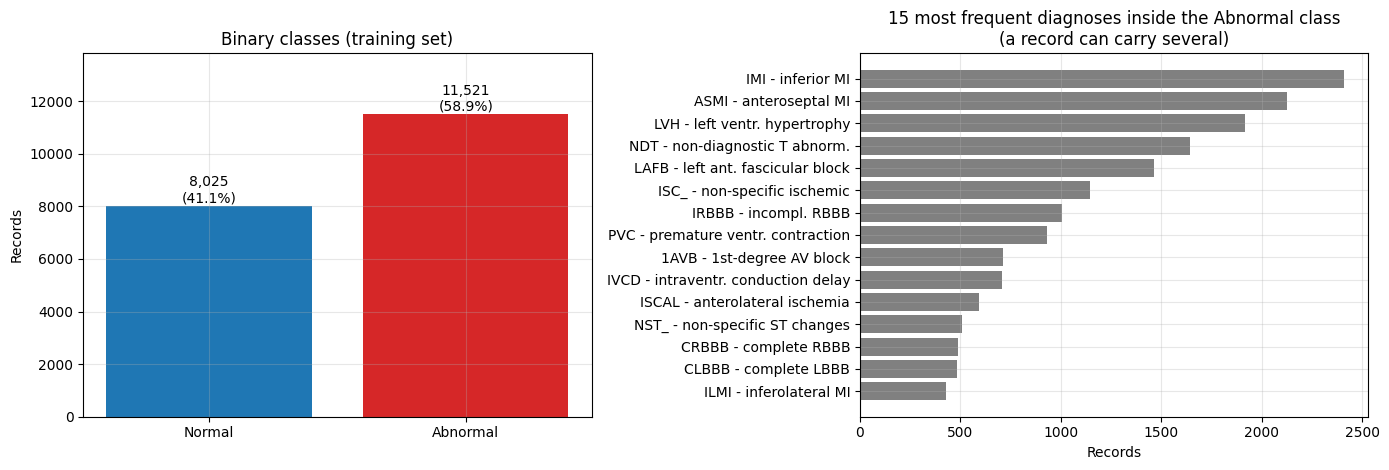

Abnormal is a mix of many different conditions, so the model has to learn a broad 'not normal' pattern.


In [10]:
CODE_MEANING = {"IMI": "inferior MI", "ASMI": "anteroseptal MI", "LVH": "left ventr. hypertrophy", "NDT": "non-diagnostic T abnorm.",
                "LAFB": "left ant. fascicular block", "AFIB": "atrial fibrillation", "ISC_": "non-specific ischemic",
                "PVC": "premature ventr. contraction", "IRBBB": "incompl. RBBB", "STD_": "non-specific ST depression",
                "VCLVH": "voltage criteria LVH", "STACH": "sinus tachycardia", "1AVB": "1st-degree AV block",
                "IVCD": "intraventr. conduction delay", "SARRH": "sinus arrhythmia", "NST_": "non-specific ST changes",
                "ISCAL": "anterolateral ischemia", "SBRAD": "sinus bradycardia", "QWAVE": "Q waves present",
                "CRBBB": "complete RBBB", "CLBBB": "complete LBBB", "ILMI": "inferolateral MI", "ABQRS": "abnormal QRS"}

counts = y_train.map(NAMES).value_counts().reindex(["Normal", "Abnormal"])
ratio = counts.max() / counts.min()
print(counts.to_string()); print(f"\nImbalance ratio (majority : minority) = {ratio:.2f} : 1")

cnt = collections.Counter(k for d, yy in zip(codes_train, y_train) if yy == 1
                          for k, v in d.items() if v > 0 and k not in IGNORE_CODES)
top = cnt.most_common(15)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].bar(counts.index, counts.values, color=[COLORS[0], COLORS[1]])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax[0].set_title("Binary classes (training set)"); ax[0].set_ylabel("Records"); ax[0].margins(y=0.2)
labels = [f"{k} - {CODE_MEANING[k]}" if k in CODE_MEANING else k for k, _ in top][::-1]
ax[1].barh(labels, [v for _, v in top][::-1], color="gray")
ax[1].set_title("15 most frequent diagnoses inside the Abnormal class\n(a record can carry several)"); ax[1].set_xlabel("Records")
plt.tight_layout(); plt.show()
print("Abnormal is a mix of many different conditions, so the model has to learn a broad 'not normal' pattern.")

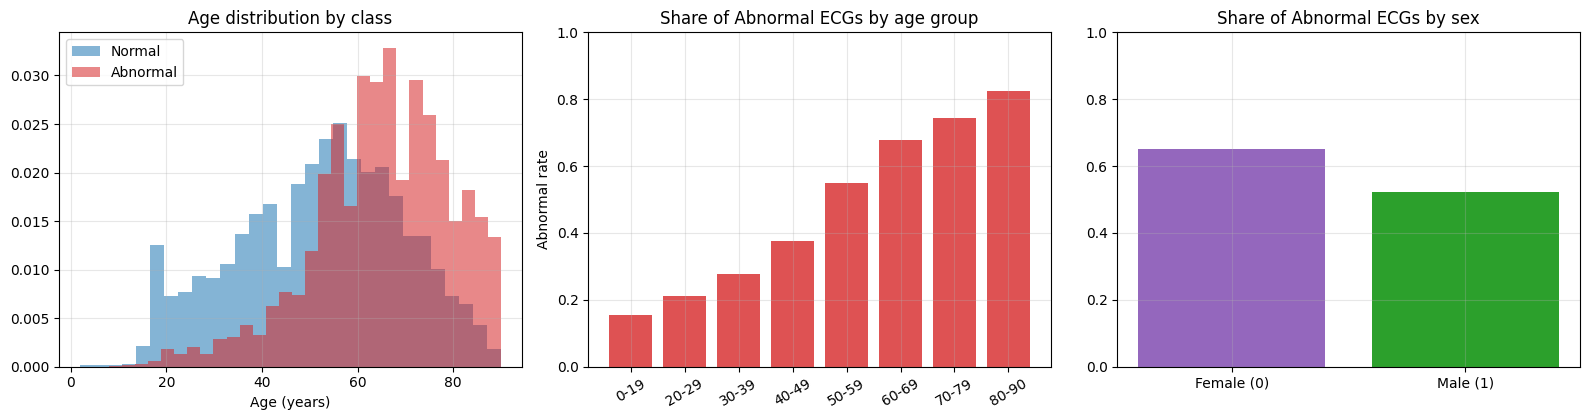

Missing height / weight in training data: 68% / 57%


In [11]:
# 3.2 Demographics vs. class
d_tr = demo.loc[ids_train].reset_index(drop=True)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for cls in [0, 1]:
    ax[0].hist(d_tr.loc[y_train == cls, "age"], bins=30, alpha=0.55, density=True, color=COLORS[cls], label=NAMES[cls])
ax[0].set_title("Age distribution by class"); ax[0].set_xlabel("Age (years)"); ax[0].legend()

bins = pd.cut(d_tr["age"], [0, 20, 30, 40, 50, 60, 70, 80, 91], right=False)
rate = y_train.groupby(bins).mean()
ax[1].bar(range(len(rate)), rate.values, color="tab:red", alpha=0.8)
ax[1].set_xticks(range(len(rate))); ax[1].set_xticklabels([f"{int(i.left)}-{int(i.right) - 1}" for i in rate.index], rotation=30)
ax[1].set_title("Share of Abnormal ECGs by age group"); ax[1].set_ylabel("Abnormal rate"); ax[1].set_ylim(0, 1)

sr = y_train.groupby(d_tr["sex"]).mean()
ax[2].bar(["Female (0)", "Male (1)"], [sr.get(0, np.nan), sr.get(1, np.nan)], color=["tab:purple", "tab:green"])
ax[2].set_title("Share of Abnormal ECGs by sex"); ax[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()
print("Missing height / weight in training data: {:.0%} / {:.0%}".format(d_tr["height"].isna().mean(), d_tr["weight"].isna().mean()))

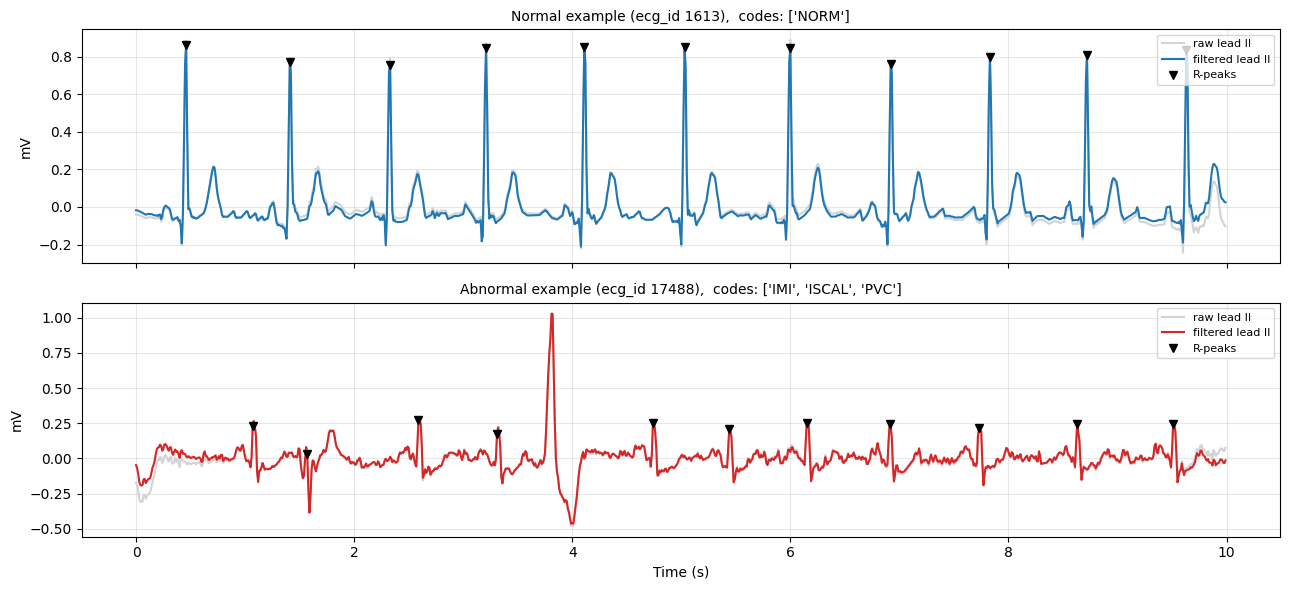

In [12]:
# 3.3 Example ECGs with detected R-peaks (waveform mode)
if use_wf:
    rng = np.random.default_rng(RANDOM_STATE)
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    for ax_, cls in zip(axes, [0, 1]):
        i = rng.choice(np.where(y_train.values == cls)[0])
        rec_id = ids_train[i]
        sig, _ = wfdb.rdsamp(os.path.join(wf_root, meta.loc[rec_id, FILENAME_COL]))
        xf = preprocess_signal(sig)
        pk = find_peaks_any_lead(xf)
        t = np.arange(len(sig)) / FS
        ax_.plot(t, sig[:, 1], color="lightgray", label="raw lead II")
        ax_.plot(t, xf[:, 1], color=COLORS[cls], label="filtered lead II")
        ax_.plot(pk / FS, xf[pk, 1], "kv", label="R-peaks")
        shown = [k for k, v in meta.loc[rec_id, "codes"].items() if v > 0]
        ax_.set_title(f"{NAMES[cls]} example (ecg_id {rec_id}),  codes: {shown}", fontsize=10); ax_.set_ylabel("mV"); ax_.legend(loc="upper right", fontsize=8)
    axes[1].set_xlabel("Time (s)"); plt.tight_layout(); plt.show()
else:
    print("Metadata mode: no waveforms to plot.")

Top features by standardised mean difference (Abnormal vs Normal):
AVR_t_amp       0.94
V6_t_amp        0.85
I_t_amp         0.83
V5_t_amp        0.79
age             0.77
II_t_amp        0.76
AVL_std         0.69
AVL_qrs_area    0.67
III_qrs_min     0.66
AVF_skew        0.66


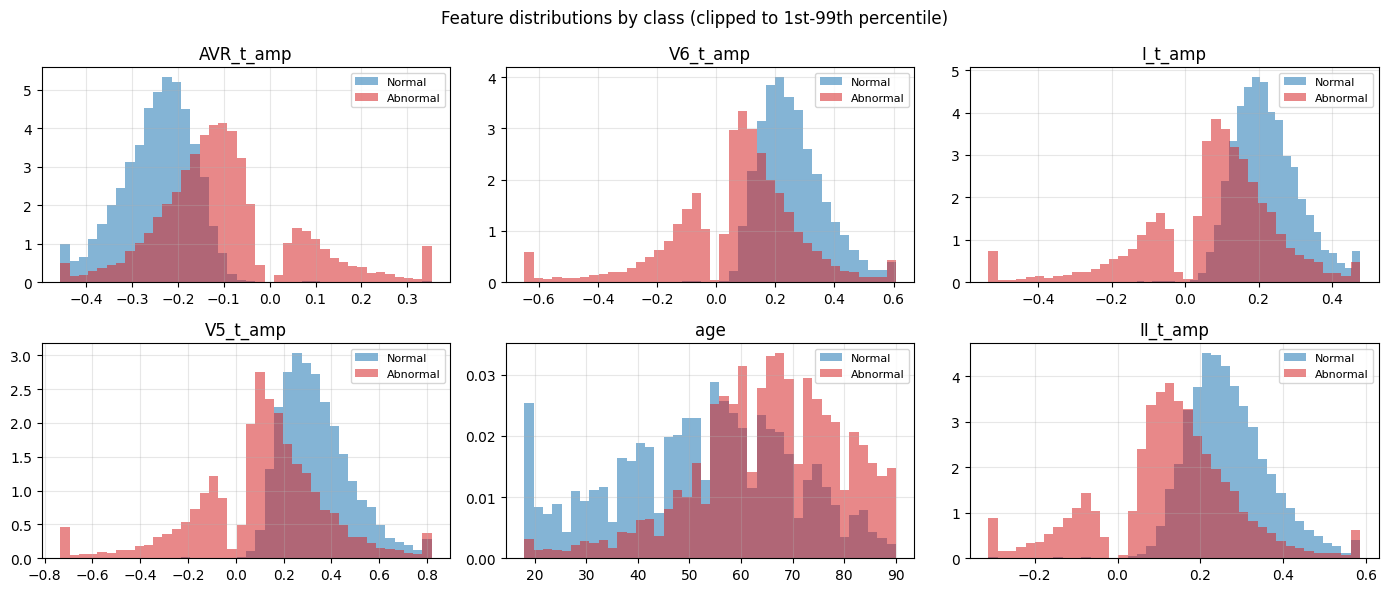

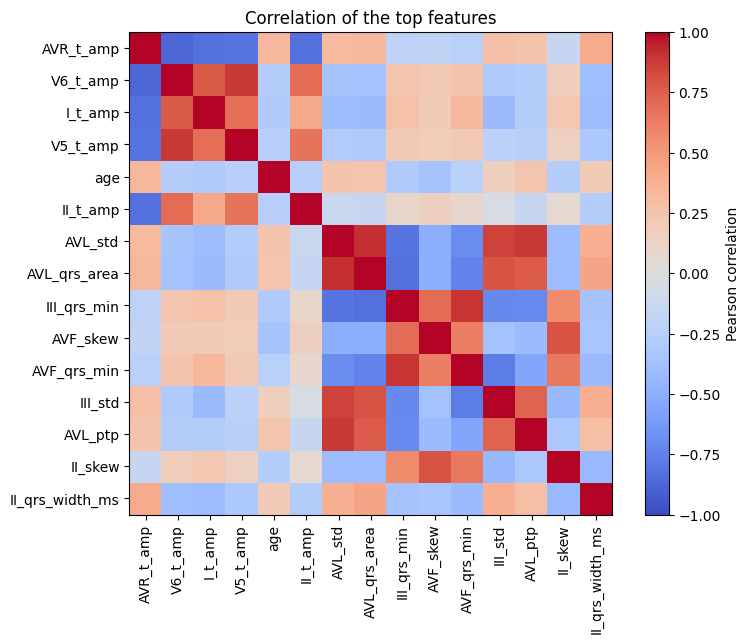

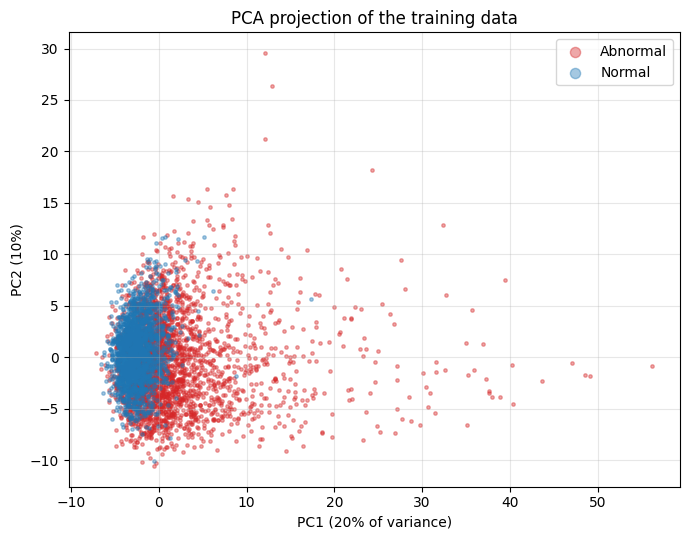

In [13]:
# 3.4 Which features differ most between Normal and Abnormal?
E = X_train
m0, m1 = E[y_train.values == 0].mean(), E[y_train.values == 1].mean()
effect = ((m1 - m0) / (E.std() + 1e-12)).abs().sort_values(ascending=False).dropna()
print("Top features by standardised mean difference (Abnormal vs Normal):")
print(effect.head(10).round(2).to_string())

top6 = list(effect.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for a in axes.ravel()[len(top6):]:
    a.axis("off")
for a, c in zip(axes.ravel(), top6):
    lo, hi = E[c].quantile([0.01, 0.99])
    for cls in [0, 1]:
        a.hist(E.loc[y_train.values == cls, c].clip(lo, hi).dropna(), bins=40, alpha=0.55, density=True, color=COLORS[cls], label=NAMES[cls])
    a.set_title(str(c)); a.legend(fontsize=8)
plt.suptitle("Feature distributions by class (clipped to 1st-99th percentile)"); plt.tight_layout(); plt.show()

# 3.5 Correlation heatmap of the top features and PCA projection
cols = list(effect.index[:min(15, len(effect))])
corr = E[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols); ax.grid(False)
plt.colorbar(im, label="Pearson correlation"); ax.set_title("Correlation of the top features"); plt.tight_layout(); plt.show()

if X_train.shape[1] >= 8:
    sel = np.random.default_rng(RANDOM_STATE).choice(len(X_train), min(5000, len(X_train)), replace=False)
    Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_train.iloc[sel]))
    pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z)
    P = pca.transform(Z)
    plt.figure(figsize=(7, 5.5))
    for cls in [1, 0]:
        mk = y_train.values[sel] == cls
        plt.scatter(P[mk, 0], P[mk, 1], s=6, alpha=0.4, color=COLORS[cls], label=NAMES[cls])
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    plt.title("PCA projection of the training data"); plt.legend(markerscale=3); plt.tight_layout(); plt.show()

## Step 4: Model training and comparison
Seven basic models are compared with **5-fold cross-validation on the training set**, with folds grouped by `patient_id` (so one patient never appears in both the training and validation part of a fold). Each model sits in a `Pipeline` (median imputation, then scaling, then classifier), so imputing and scaling are fitted inside each fold only. Models that support it use `class_weight="balanced"` against class imbalance.

In [14]:
def make_pipe(model):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("model", model)])

models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    "KNN":                 make_pipe(KNeighborsClassifier(n_neighbors=15)),
    "Naive Bayes":         make_pipe(GaussianNB()),
    "Decision Tree":       make_pipe(DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest":       make_pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=RANDOM_STATE)),
    "SVM (RBF)":           make_pipe(SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
    "Gradient Boosting":   make_pipe(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
}

def make_cv():
    return StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

def jobs_for(name):                  # Gradient Boosting already uses all CPU cores internally
    return 1 if name == "Gradient Boosting" else -1

# Large training sets: compare/tune on a stratified subset (the final model is fitted on ALL training rows)
if len(y_train) > CV_MAX_SAMPLES:
    sub, _ = train_test_split(np.arange(len(y_train)), train_size=CV_MAX_SAMPLES, stratify=y_train, random_state=RANDOM_STATE)
    print(f"Using a stratified subset of {CV_MAX_SAMPLES:,} training rows for model comparison and tuning.")
else:
    sub = np.arange(len(y_train))
X_cv, y_cv = X_train.iloc[sub].reset_index(drop=True), y_train.iloc[sub].reset_index(drop=True)
g_cv = g_train.iloc[sub].reset_index(drop=True)

METRICS = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]
cv_results, fold_scores = {}, {}
for name, pipe in models.items():
    t0 = time.time()
    res = cross_validate(pipe, X_cv, y_cv, cv=make_cv(), groups=g_cv, scoring=METRICS, n_jobs=jobs_for(name))
    cv_results[name] = {m: res[f"test_{m}"].mean() for m in METRICS} | {"fit_time_s": res["fit_time"].mean()}
    fold_scores[name] = res[f"test_{SELECTION_METRIC}"]
    print(f"{name:<20} {SELECTION_METRIC} = {fold_scores[name].mean():.4f} (+/- {fold_scores[name].std():.4f})   [{time.time() - t0:.0f}s]")

cv_table = pd.DataFrame(cv_results).T.sort_values(SELECTION_METRIC, ascending=False)
pd.set_option("display.width", 200, "display.max_columns", 20)
print("\nCross-validation results (mean over folds; precision/recall/f1 refer to the Abnormal class):")
display(cv_table.round(4))

Logistic Regression  balanced_accuracy = 0.8459 (+/- 0.0059)   [15s]
KNN                  balanced_accuracy = 0.8240 (+/- 0.0059)   [17s]
Naive Bayes          balanced_accuracy = 0.7345 (+/- 0.0064)   [8s]
Decision Tree        balanced_accuracy = 0.8277 (+/- 0.0016)   [23s]
Random Forest        balanced_accuracy = 0.8619 (+/- 0.0065)   [362s]
SVM (RBF)            balanced_accuracy = 0.8647 (+/- 0.0062)   [163s]
Gradient Boosting    balanced_accuracy = 0.8758 (+/- 0.0028)   [29s]

Cross-validation results (mean over folds; precision/recall/f1 refer to the Abnormal class):


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,fit_time_s
Gradient Boosting,0.8725,0.8758,0.9205,0.8579,0.8881,0.9460,4.4366
SVM (RBF),0.8580,0.8647,0.9234,0.8278,0.8729,0.9369,34.8447
Random Forest,0.8668,0.8619,0.8850,0.8897,0.8873,0.9401,124.0999
Logistic Regression,0.8398,0.8459,0.9064,0.8121,0.8566,0.9199,2.1185
Decision Tree,0.8150,0.8277,0.9145,0.7575,0.8283,0.8689,5.6998
KNN,0.8063,0.8240,0.9306,0.7255,0.8153,0.9053,0.6145
Naive Bayes,0.6934,0.7345,0.9521,0.5054,0.6602,0.8784,0.6892


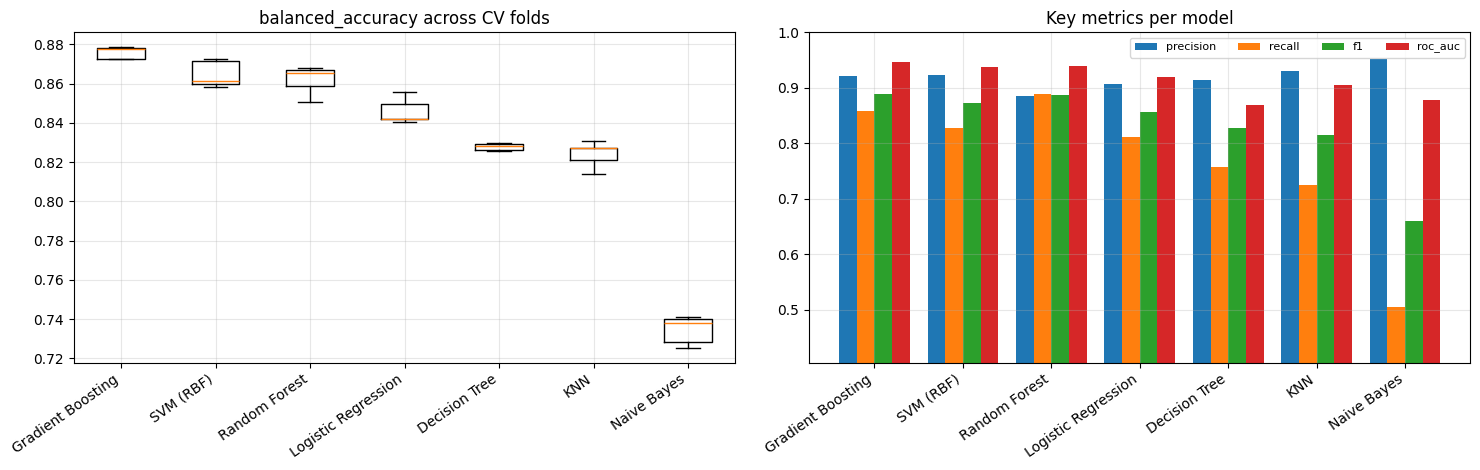

Best model by cross-validated balanced_accuracy: Gradient Boosting


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
order = list(cv_table.index)
ax[0].boxplot([fold_scores[n] for n in order])
ax[0].set_xticklabels(order, rotation=35, ha="right")
ax[0].set_title(f"{SELECTION_METRIC} across CV folds")
w = 0.2
for j, m in enumerate(["precision", "recall", "f1", "roc_auc"]):
    ax[1].bar(np.arange(len(order)) + (j - 1.5) * w, cv_table.loc[order, m], w, label=m)
ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels(order, rotation=35, ha="right")
ax[1].set_ylim(max(0, cv_table[["precision", "recall", "f1", "roc_auc"]].min().min() - 0.1), 1.0)
ax[1].set_title("Key metrics per model"); ax[1].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

best_name = cv_table.index[0]
print(f"Best model by cross-validated {SELECTION_METRIC}: {best_name}")

## Step 5: Tune the best model and evaluate it
A small grid search is run for the winning model (cross-validation on training data only). The tuned model is then refitted on **all** training data.

Metrics, with *Abnormal* as the "positive" class:
- **Recall (sensitivity):** share of abnormal ECGs that were caught. Missing a disease is usually the costly error.
- **Specificity:** share of normal ECGs correctly called normal.
- **Precision:** when the model says "abnormal", how often it is right.
- **F1:** balance of precision and recall.
- **Balanced accuracy:** average of sensitivity and specificity (fair under class imbalance).
- **ROC-AUC / PR-AUC:** threshold-independent ranking quality.
- **MCC:** a single balanced score from -1 to 1.

In [16]:
PARAM_GRIDS = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "KNN":                 {"model__n_neighbors": [7, 15, 31], "model__weights": ["uniform", "distance"]},
    "Naive Bayes":         {"model__var_smoothing": [1e-9, 1e-8, 1e-7]},
    "Decision Tree":       {"model__max_depth": [4, 8, 12], "model__min_samples_leaf": [5, 20, 50]},
    "Random Forest":       {"model__max_depth": [None, 20], "model__min_samples_leaf": [1, 3]},
    "SVM (RBF)":           {"model__C": [1, 10], "model__gamma": ["scale", 0.01]},
    "Gradient Boosting":   {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31]},
}

t0 = time.time()
grid = GridSearchCV(models[best_name], PARAM_GRIDS[best_name], scoring=SELECTION_METRIC, cv=make_cv(),
                    n_jobs=jobs_for(best_name), refit=False)
grid.fit(X_cv, y_cv, groups=g_cv)
print(f"Grid search for {best_name} finished in {time.time() - t0:.0f}s")
print("Best parameters:", grid.best_params_)
print(f"Best CV {SELECTION_METRIC}: {grid.best_score_:.4f}")

final_model = clone(models[best_name]).set_params(**grid.best_params_)      # refit on ALL training rows
t0 = time.time()
final_model.fit(X_train, y_train)
print(f"Final model fitted on {len(y_train):,} training rows ({time.time() - t0:.0f}s)")

Grid search for Gradient Boosting finished in 87s
Best parameters: {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}
Best CV balanced_accuracy: 0.8758
Final model fitted on 19,546 training rows (5s)


Cross-validated performance of the tuned Gradient Boosting:


,CV
accuracy,0.8726
balanced_accuracy,0.8758
precision,0.9205
recall (sensitivity),0.8578
specificity,0.8937
f1,0.8881
roc_auc,0.9458
pr_auc,0.9648
mcc,0.7430


              precision    recall  f1-score   support

      Normal     0.8141    0.8937    0.8520      8025
    Abnormal     0.9205    0.8578    0.8881     11521

    accuracy                         0.8726     19546
   macro avg     0.8673    0.8758    0.8701     19546
weighted avg     0.8768    0.8726    0.8733     19546



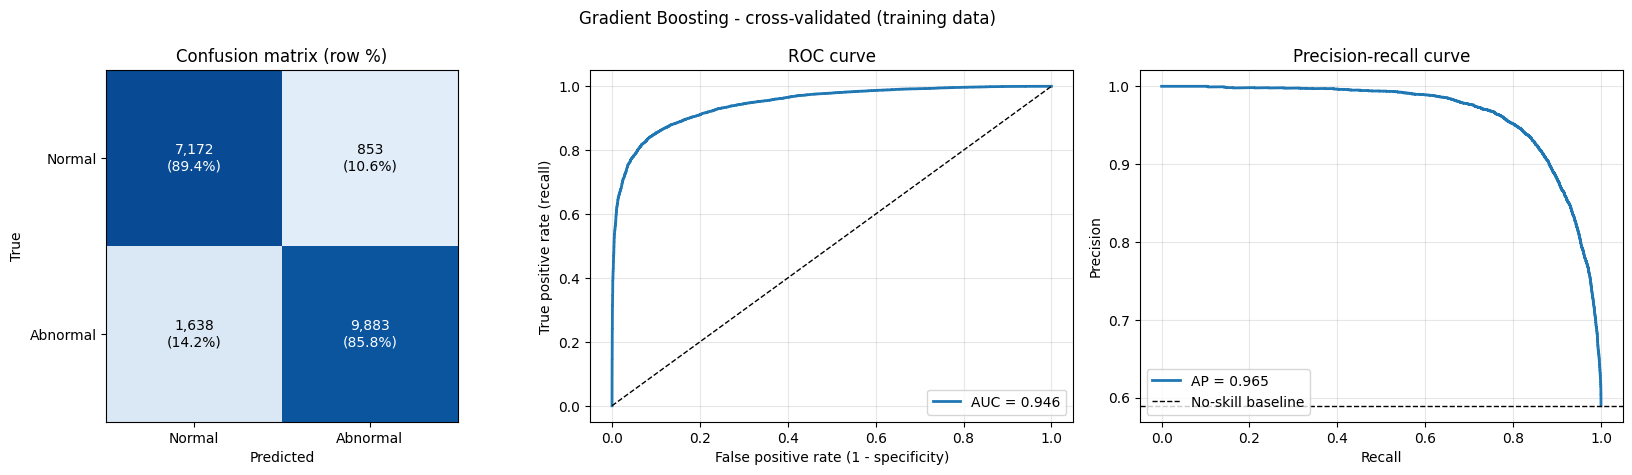

In [17]:
def get_scores(model, X):
    # a continuous "abnormality score" and the threshold that separates the two classes
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1], 0.5
    return model.decision_function(X), 0.0

def evaluate(y_true, y_pred, y_score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall (sensitivity)": recall_score(y_true, y_pred),
            "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_score),
            "pr_auc": average_precision_score(y_true, y_score),
            "mcc": matthews_corrcoef(y_true, y_pred)}

def plot_evaluation(y_true, y_pred, y_score, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax[0].grid(False)
    for i in range(2):
        for j in range(2):
            ax[0].text(j, i, f"{cm[i, j]:,}\n({cmn[i, j]:.1%})", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
    ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Normal", "Abnormal"]); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Normal", "Abnormal"])
    ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True"); ax[0].set_title("Confusion matrix (row %)")
    fpr, tpr, _ = roc_curve(y_true, y_score)
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_true, y_score):.3f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set_xlabel("False positive rate (1 - specificity)"); ax[1].set_ylabel("True positive rate (recall)"); ax[1].set_title("ROC curve"); ax[1].legend(loc="lower right")
    pr, rc, _ = precision_recall_curve(y_true, y_score)
    ax[2].plot(rc, pr, lw=2, label=f"AP = {average_precision_score(y_true, y_score):.3f}")
    ax[2].axhline(np.mean(y_true), color="k", ls="--", lw=1, label="No-skill baseline")
    ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("Precision-recall curve"); ax[2].legend(loc="lower left")
    plt.suptitle(title); plt.tight_layout(); plt.show()

# Out-of-fold predictions on training data: an honest estimate that never touches the test set
method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"
oof = cross_val_predict(clone(final_model), X_cv, y_cv, cv=make_cv(), groups=g_cv, method=method, n_jobs=jobs_for(best_name))
oof_score = oof[:, 1] if oof.ndim == 2 else oof
oof_pred = (oof_score > (0.5 if oof.ndim == 2 else 0.0)).astype(int)

cv_metrics = evaluate(y_cv, oof_pred, oof_score)
print(f"Cross-validated performance of the tuned {best_name}:")
display(pd.Series(cv_metrics, name="CV").round(4).to_frame())
print(classification_report(y_cv, oof_pred, target_names=["Normal", "Abnormal"], digits=4))
plot_evaluation(y_cv.values, oof_pred, oof_score, f"{best_name} - cross-validated (training data)")

## Step 6: Final test on unseen data
The test set has not been used for anything so far (not for EDA, model selection or tuning). It is the best available estimate of how the model behaves on new patients.

FINAL MODEL: Gradient Boosting   |   mode: waveform   |   test records: 2,192


,Cross-validation (train),Unseen test set,gap (test - CV)
accuracy,0.8726,0.8531,-0.0195
balanced_accuracy,0.8758,0.8611,-0.0146
precision,0.9205,0.9257,0.0052
recall (sensitivity),0.8578,0.8171,-0.0407
specificity,0.8937,0.9051,0.0114
f1,0.8881,0.8680,-0.0200
roc_auc,0.9458,0.9297,-0.0161
pr_auc,0.9648,0.9569,-0.0079
mcc,0.7430,0.7108,-0.0322


              precision    recall  f1-score   support

      Normal     0.7739    0.9051    0.8344       896
    Abnormal     0.9257    0.8171    0.8680      1296

    accuracy                         0.8531      2192
   macro avg     0.8498    0.8611    0.8512      2192
weighted avg     0.8636    0.8531    0.8543      2192



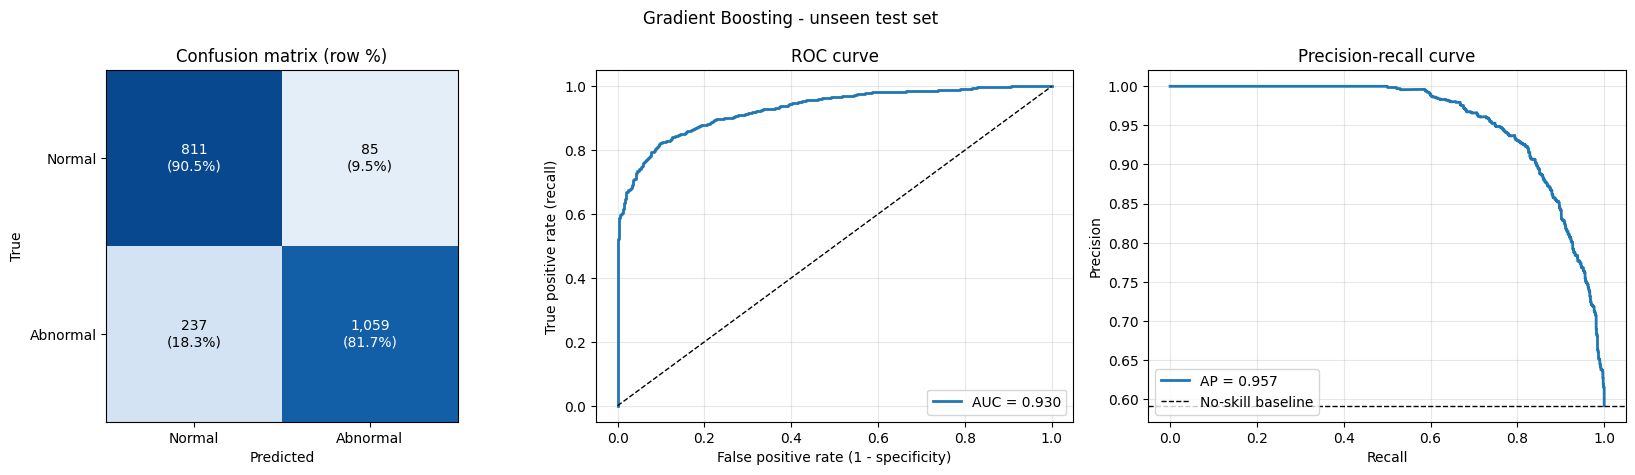


95% bootstrap confidence intervals on the test set:
  f1                 0.8676  [0.8529, 0.8827]
  recall             0.8163  [0.7947, 0.8361]
  balanced_accuracy  0.8609  [0.8472, 0.8762]

Generalisation check: test F1 differs from cross-validated F1 by -0.0200.
A small gap means the model generalises; a much lower test score suggests overfitting.


In [18]:
score_test, thr = get_scores(final_model, X_test)
pred_test = (score_test > thr).astype(int)

test_metrics = evaluate(y_test, pred_test, score_test)
comparison = pd.DataFrame({"Cross-validation (train)": cv_metrics, "Unseen test set": test_metrics})
comparison["gap (test - CV)"] = comparison.iloc[:, 1] - comparison.iloc[:, 0]
print(f"FINAL MODEL: {best_name}   |   mode: {'waveform' if use_wf else 'metadata only'}   |   test records: {len(y_test):,}")
display(comparison.round(4))
print(classification_report(y_test, pred_test, target_names=["Normal", "Abnormal"], digits=4))
plot_evaluation(y_test.values, pred_test, score_test, f"{best_name} - unseen test set")

# 95% bootstrap confidence intervals: how much would the numbers change with a different test sample?
rng = np.random.default_rng(RANDOM_STATE)
yt, yp = y_test.values, pred_test
boot = {"f1": [], "recall": [], "balanced_accuracy": []}
for _ in range(500):
    b = rng.integers(0, len(yt), len(yt))
    boot["f1"].append(f1_score(yt[b], yp[b])); boot["recall"].append(recall_score(yt[b], yp[b]))
    boot["balanced_accuracy"].append(balanced_accuracy_score(yt[b], yp[b]))
print("\n95% bootstrap confidence intervals on the test set:")
for k, v in boot.items():
    print(f"  {k:<18} {np.mean(v):.4f}  [{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]")

gap = comparison.loc["f1", "gap (test - CV)"]
print(f"\nGeneralisation check: test F1 differs from cross-validated F1 by {gap:+.4f}.")
print("A small gap means the model generalises; a much lower test score suggests overfitting.")

## Step 7: Export the deployment bundle
This cell packages the **already trained** model (no retraining) together with the complete inference configuration, feature schema, metadata, permutation importances and reference test vectors, ready for the Streamlit application (`models/ptbxl_binary_model.joblib`, `models/model_metadata.json`).

In [ ]:
# Which features did the model rely on? (tree-based models) / or coefficients (logistic regression)
clf = final_model.named_steps["model"]
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
    title = f"Top 15 feature importances - {best_name}"
elif hasattr(clf, "coef_"):
    imp = pd.Series(np.abs(clf.coef_[0]), index=X_train.columns).sort_values(ascending=False).head(15)
    title = f"Top 15 |coefficients| (standardised features) - {best_name}"
else:
    imp = None
    print(f"{best_name} has no built-in feature importances.")
if imp is not None:
    plt.figure(figsize=(7, 5)); plt.barh(imp.index[::-1], imp.values[::-1], color="seagreen")
    plt.title(title); plt.tight_layout(); plt.show()

# ======================================================================================================
#  EXPORT: complete deployment bundle for the Streamlit CAD application   (replaces the old export cell)
#  Nothing is retrained: this cell only packages the model that was fitted above, plus everything the
#  inference pipeline needs to reproduce this notebook's preprocessing and feature extraction.
# ======================================================================================================
import os, json, platform, datetime as dt
from importlib import metadata as _md
import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

EXPORT_DIR = os.path.join(DATA_DIR, "models")           # copy this folder into the app project  (models/)
os.makedirs(EXPORT_DIR, exist_ok=True)

# ---- 1. inference configuration (snapshot of the feature-extraction cell above; identical to modules/config.py)
INFERENCE_CONFIG = json.loads(r"""{
 "model_fs_hz": 100,
 "n_leads": 12,
 "lead_names": [
  "I",
  "II",
  "III",
  "AVR",
  "AVL",
  "AVF",
  "V1",
  "V2",
  "V3",
  "V4",
  "V5",
  "V6"
 ],
 "window_s": 10.0,
 "bandpass": {
  "kind": "butterworth_bandpass",
  "order": 2,
  "low_hz": 0.5,
  "high_hz": 40.0,
  "zero_phase": true,
  "implementation": "scipy.signal.sosfiltfilt (sos)"
 },
 "qrs_detection": {
  "algorithm": "Pan-Tompkins-style (custom, from notebook)",
  "band_hz": [
   5,
   15
  ],
  "band_order": 2,
  "smoothing_window_s": 0.12,
  "threshold_fraction": 0.35,
  "threshold_percentile": 99,
  "min_distance_s": 0.25,
  "refine_half_window_s": 0.06,
  "min_peak_spacing_s": 0.2,
  "peak_leads": [
   1,
   0,
   10,
   7
  ],
  "min_peaks": 3
 },
 "template": {
  "pre_s": 0.25,
  "post_s": 0.45,
  "min_beats": 2,
  "baseline_window_s": [
   -0.08,
   -0.04
  ],
  "qrs_window_s": [
   -0.06,
   0.08
  ],
  "width_window_s": [
   -0.12,
   0.12
  ],
  "width_fraction": 0.2,
  "st_window_s": [
   0.08,
   0.12
  ],
  "t_window_s": [
   0.15,
   0.4
  ],
  "p_window_s": [
   -0.2,
   -0.1
  ]
 },
 "rhythm_features": [
  "hr_bpm",
  "mean_rr_s",
  "sdnn_s",
  "rmssd_s",
  "pnn50",
  "rr_cv",
  "rr_range_s",
  "n_beats"
 ],
 "lead_stat_features": [
  "std",
  "ptp",
  "skew",
  "kurt"
 ],
 "template_features": [
  "qrs_max",
  "qrs_min",
  "qrs_area",
  "qrs_width_ms",
  "st_dev",
  "t_amp",
  "p_amp"
 ],
 "demographics": {
  "feature_order": [
   "age",
   "sex",
   "height",
   "weight",
   "bmi"
  ],
  "age_cap_threshold": 120,
  "age_cap_value": 90,
  "height_cm_valid_range": [
   50,
   230
  ],
  "weight_kg_valid_range": [
   3,
   250
  ],
  "bmi_valid_range": [
   8,
   70
  ],
  "sex_coding": {
   "male": 0,
   "female": 1
  },
  "median_imputation_of_missing": true
 }
}""")
CLASS_MAPPING = {0: "Normal", 1: "Abnormal"}
LIMITATIONS = json.loads(r"""[
 "Research/educational model trained on PTB-XL; not validated for clinical decision making.",
 "'Abnormal' merges many different diagnoses; per-diagnosis performance was not analysed.",
 "Trained on 10-s, 12-lead recordings at 100 Hz; other sampling rates are resampled (not part of the original pipeline).",
 "Age is among the strongest predictors; predictions without age/sex are less reliable.",
 "The R-peak detector can miss wide ectopic (PVC) beats, affecting rhythm features.",
 "No external validation (other hospitals/devices) has been performed."
]""")

# ---- 2. feature schema: the exact names and order the model was trained on, verified against the config
FEATURE_NAMES = list(X_train.columns)
expected = list(INFERENCE_CONFIG["rhythm_features"])
for _lead in INFERENCE_CONFIG["lead_names"]:
    expected += [f"{_lead}_{n}" for n in INFERENCE_CONFIG["lead_stat_features"] + INFERENCE_CONFIG["template_features"]]
expected += list(INFERENCE_CONFIG["demographics"]["feature_order"])
assert FEATURE_NAMES == expected, (
    "The model's training columns differ from the expected 140 waveform + 5 demographic feature schema "
    "(was FEATURE_SET changed, or USE_DEMOGRAPHICS=False?). The deployment pipeline cannot reproduce this model.")
assert list(final_model.named_steps) == ["impute", "scale", "model"], "unexpected pipeline structure"
assert final_model.n_features_in_ == len(FEATURE_NAMES) == 145
_est = final_model.named_steps["model"]
assert type(_est).__name__ == "HistGradientBoostingClassifier", f"selected model is {type(_est).__name__}"

THRESHOLD = float(thr)                                   # decision threshold used in the final test (0.5)

# ---- 3. training-feature distribution (lets the app flag unusual feature values)
_q = X_train.quantile([0.01, 0.05, 0.5, 0.95, 0.99]).T
TRAIN_SUMMARY = {n: {"mean": float(X_train[n].mean()), "std": float(X_train[n].std()), "p01": float(_q.loc[n, 0.01]),
                     "p05": float(_q.loc[n, 0.05]), "p50": float(_q.loc[n, 0.5]), "p95": float(_q.loc[n, 0.95]),
                     "p99": float(_q.loc[n, 0.99]), "missing_fraction": float(X_train[n].isna().mean())}
                 for n in X_train.columns}

# ---- 4. global explanation: permutation importance on the held-out test set (the model has no built-in importances)
print("Computing permutation importance on the test set (about a minute) ...")
_pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=5,
                             random_state=RANDOM_STATE, n_jobs=1)
GLOBAL_IMPORTANCE = {
    "method": "permutation importance (sklearn.inspection.permutation_importance)", "scoring": "roc_auc",
    "n_repeats": 5, "dataset": "test (PTB-XL strat_fold 10)", "n_samples": int(len(X_test)),
    "importances": {n: {"mean": float(m), "std": float(s)} for n, m, s in zip(X_test.columns, _pi.importances_mean, _pi.importances_std)}}

def _versions():
    out = {"python": platform.python_version()}
    for _p in ["scikit-learn", "numpy", "scipy", "pandas", "joblib", "wfdb", "matplotlib"]:
        try:
            out[_p] = _md.version(_p)
        except _md.PackageNotFoundError:
            pass
    return out

# ---- 5. metadata (only values that exist in this notebook session - nothing invented)
_perf = {k.replace("recall (sensitivity)", "sensitivity"): round(float(v), 4) for k, v in test_metrics.items()}
_perf.update(n_test_records=int(len(y_test)), test_set="PTB-XL strat_fold 10")
_params = _est.get_params()
METADATA = {
    "model_name": "PTB-XL binary ECG classifier (Normal vs Abnormal)", "model_version": "1.0.0",
    "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "is_test_stub": False,
    "task": "Binary classification of 12-lead ECG: 0 = Normal, 1 = Abnormal",
    "algorithm": type(_est).__name__,
    "hyperparameters": {k: _params[k] for k in ["learning_rate", "max_leaf_nodes", "max_iter", "max_depth", "min_samples_leaf",
                                                "l2_regularization", "class_weight", "random_state", "early_stopping"] if k in _params},
    "pipeline_steps": ["impute (median)", "scale (StandardScaler)", "model (HistGradientBoostingClassifier)"],
    "selection": {"procedure": f"{N_FOLDS}-fold patient-grouped stratified cross-validation, model comparison + grid search",
                  "metric": SELECTION_METRIC, "selected_model": best_name, "best_params": {k: v for k, v in grid.best_params_.items()}},
    "decision_threshold": THRESHOLD, "class_mapping": {str(k): v for k, v in CLASS_MAPPING.items()},
    "sampling_frequency_hz": INFERENCE_CONFIG["model_fs_hz"], "n_leads": INFERENCE_CONFIG["n_leads"],
    "lead_names": INFERENCE_CONFIG["lead_names"], "n_features": len(FEATURE_NAMES), "feature_names": FEATURE_NAMES,
    "training_info": {"data": "PTB-XL", "signal_source": f"{REC_DIRS[rec_type]} ({FS} Hz)", "split": SPLIT_MODE,
                      "n_train_records": int(len(y_train)), "n_test_records": int(len(y_test)),
                      "n_train_patients": int(g_train.nunique()), "abnormal_share_train": round(float(y_train.mean()), 4),
                      "random_state": RANDOM_STATE, "cv_folds": N_FOLDS, "cv_max_samples": CV_MAX_SAMPLES,
                      "label_rule": f"Normal = NORM likelihood >= {NORMAL_MIN_LIKELIHOOD} and no other diagnosis; Abnormal = any other diagnosis"},
    "performance_recorded_in_notebook": _perf,
    "library_versions": _versions(),
    "limitations": LIMITATIONS,
    "notes": ["QRS width (qrs_width_ms) is measured at 20 % of the peak height: this is what the cached training features used (verified exactly on 30 test records). Notebook feature cell 12 as written says 10 %, which does NOT reproduce the training features.",
              "Library versions are those of the Colab runtime that ran this cell. If the runtime was restarted after the model "
              "was fitted and the model was re-loaded from disk, they may differ from the training session."],
}

# ---- 6. reference vectors: 30 test records (15 Normal + 15 Abnormal) with the features and probabilities THIS notebook produced
_rng = np.random.default_rng(RANDOM_STATE)
_pick = np.sort(np.concatenate([_rng.choice(np.where(y_test.values == c)[0], 15, replace=False) for c in (0, 1)]))
_ref = X_test.iloc[_pick].reset_index(drop=True).copy()
_ref.insert(0, "p_abnormal", final_model.predict_proba(X_test.iloc[_pick])[:, 1])
_ref.insert(0, "label", y_test.values[_pick])
_ref.insert(0, "record_path", meta.loc[test_mask, FILENAME_COL].values[_pick])
_ref.insert(0, "ecg_id", meta.index[test_mask].values[_pick])

# ---- 7. write everything
BUNDLE = {
    "format_version": 2, "model": final_model, "feature_names": FEATURE_NAMES, "threshold": THRESHOLD,
    "class_mapping": CLASS_MAPPING, "sampling_frequency_hz": INFERENCE_CONFIG["model_fs_hz"],
    "n_leads": INFERENCE_CONFIG["n_leads"], "lead_names": INFERENCE_CONFIG["lead_names"], "waveform_mode": True,
    "demographics_config": INFERENCE_CONFIG["demographics"], "inference_config": INFERENCE_CONFIG,
    "metadata": METADATA, "training_feature_summary": TRAIN_SUMMARY, "global_importance": GLOBAL_IMPORTANCE}
joblib.dump(BUNDLE, os.path.join(EXPORT_DIR, "ptbxl_binary_model.joblib"), compress=3)
with open(os.path.join(EXPORT_DIR, "model_metadata.json"), "w") as fh:
    json.dump({**METADATA, "has_global_importance": True, "has_training_feature_summary": True}, fh, indent=2, default=str)
pd.DataFrame(GLOBAL_IMPORTANCE["importances"]).T.sort_values("mean", ascending=False).to_csv(
    os.path.join(EXPORT_DIR, "permutation_importance.csv"))
_ref.to_csv(os.path.join(EXPORT_DIR, "reference_test_vectors.csv"), index=False)

# ---- 8. self-check: reload the file and confirm it reproduces this notebook's probabilities exactly
_re = joblib.load(os.path.join(EXPORT_DIR, "ptbxl_binary_model.joblib"))
_same = np.allclose(_re["model"].predict_proba(X_test[_re["feature_names"]])[:, 1],
                    final_model.predict_proba(X_test)[:, 1], rtol=0, atol=1e-12)
assert _same, "reloaded model does not reproduce the notebook's test probabilities"
print("Saved to:", EXPORT_DIR)
for _f in sorted(os.listdir(EXPORT_DIR)):
    print(f"  {_f:<32} {os.path.getsize(os.path.join(EXPORT_DIR, _f)) / 1024:9.1f} KB")
print(f"Reload check passed: identical probabilities on all {len(X_test):,} test records.")
print("NEXT: copy the 'models' folder into the app project and run  python scripts/verify_consistency.py")
